# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Registration: 026 | Name: Muhammad Ismail | Total: 25 marks**

Open this notebook in Google Colab and choose **Runtime → Run all**. A CPU runtime is sufficient. The first run downloads BloodMNIST. Read the explanations and inspect the outputs before submitting.

## Prediction — write before running the experiment (Q4, 1 mark)
I predict HOG will lose more accuracy under rotation because rotating the cell changes the gradient directions in its fixed orientation bins. I predict HOG will also lose more accuracy under noise because pixel noise introduces extra local gradients; SIFT's descriptor smoothing may reduce some of that effect. These are hypotheses to test, not measured conclusions; fixed-grid SIFT is not guaranteed to be rotation invariant.

## Personal settings — first code cell
Only the last two registration digits set the seed. The last digit sets the HOG cell size and SIFT grid size. For 026, these are **26**, **8 × 8**, and **6 × 6**.

In [2]:
ROLL_NO = "026"
NAME = "Muhammad Ismail"  # Replace with your name before submission.
SEED = int(ROLL_NO[-2:])
last_digit = int(ROLL_NO[-1])
HOG_CELL = 8 if last_digit % 2 == 0 else 16
SIFT_GRID = 4 if last_digit <= 4 else 6
print("Seed:", SEED, "| HOG cell:", HOG_CELL, "| SIFT grid:", SIFT_GRID)


Seed: 26 | HOG cell: 8 | SIFT grid: 6


In [3]:
import sys
import subprocess
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "medmnist"])
try:
    import cv2
    assert hasattr(cv2, "SIFT_create")
except (ImportError, AssertionError):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "opencv-python-headless"])
    import cv2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import medmnist
import sklearn
import skimage
from medmnist import BloodMNIST
from skimage.feature import hog
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display, Markdown
print("OpenCV:", cv2.__version__, "| medmnist:", medmnist.__version__)
print("scikit-learn:", sklearn.__version__, "| scikit-image:", skimage.__version__)


OpenCV: 5.0.0 | medmnist: 3.0.2
scikit-learn: 1.6.1 | scikit-image: 0.25.2


## Q1. Data setup (3 marks)
Use the official train, validation and test splits of **BloodMNIST at size 64**. Choose 100, 30 and 30 images per class using the personal seed. Convert each selected RGB image to grayscale and resize it to 128 × 128; float pixels are in [0, 1]. Labels keep their original IDs.

The test split is prepared to meet Q1's shape/count requirement, but it is not evaluated or used to choose settings until Q4.

In [4]:
CLASS_IDS = [1, 5, 6, 7]
CLASS_NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
NAME_BY_ID = dict(zip(CLASS_IDS, CLASS_NAMES))

def load_subset(split, per_class):
    dataset = BloodMNIST(split=split, size=64, download=True)
    labels = dataset.labels.ravel()
    rng = np.random.default_rng(SEED)
    indices = []
    for label in CLASS_IDS:
        candidates = np.flatnonzero(labels == label)
        assert len(candidates) >= per_class
        indices.extend(rng.choice(candidates, per_class, replace=False))
    indices = np.array(indices)
    rng.shuffle(indices)
    images = []
    for image in dataset.imgs[indices]:
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
        gray = cv2.resize(gray, (128, 128), interpolation=cv2.INTER_LINEAR)
        images.append(gray.astype(np.float32) / 255.0)
    return np.stack(images), labels[indices]

X_train, y_train = load_subset("train", 100)
X_val, y_val = load_subset("val", 30)
X_test, y_test = load_subset("test", 30)
for split, images, labels, count in [
    ("train", X_train, y_train, 100),
    ("validation", X_val, y_val, 30),
    ("test", X_test, y_test, 30),
]:
    counts = {NAME_BY_ID[k]: int(np.sum(labels == k)) for k in CLASS_IDS}
    print(split, "image shape:", images.shape, "label shape:", labels.shape)
    print("Class counts:", counts, "| pixel range:", images.min(), images.max())
    assert images.shape == (4 * count, 128, 128)
    assert all(value == count for value in counts.values())


train image shape: (400, 128, 128) label shape: (400,)
Class counts: {'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100} | pixel range: 0.12941177 0.92941177
validation image shape: (120, 128, 128) label shape: (120,)
Class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30} | pixel range: 0.15294118 0.9372549
test image shape: (120, 128, 128) label shape: (120,)
Class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30} | pixel range: 0.1254902 0.93333334


### Four training examples per class
Rows identify the four classes. Only training examples are displayed here.

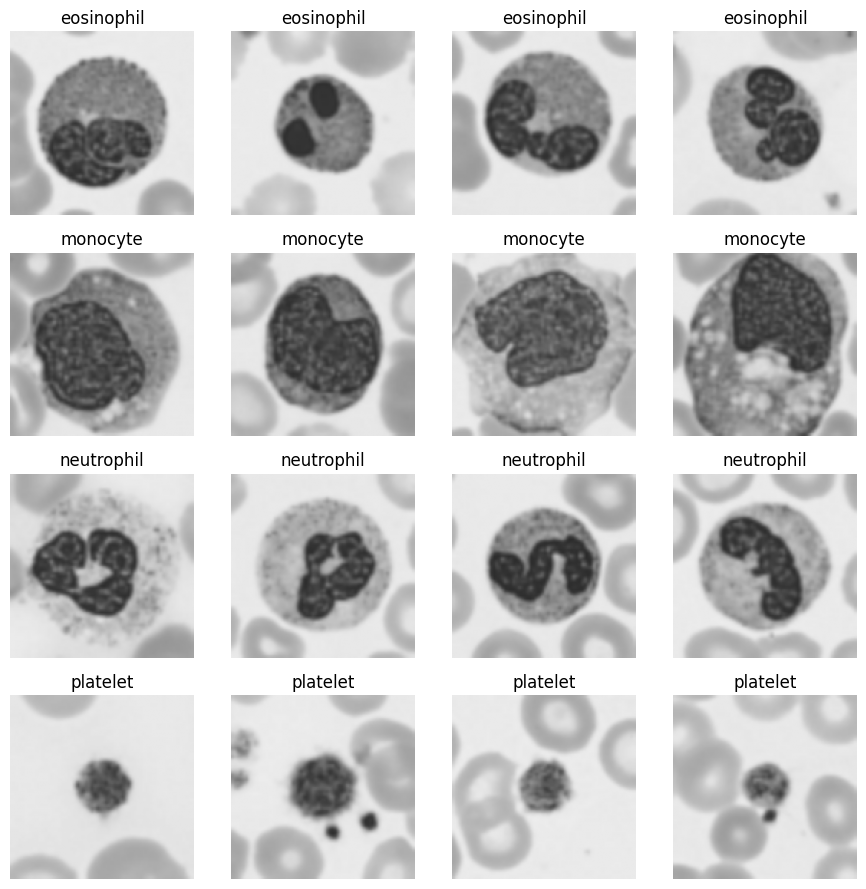

In [5]:
fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for row, label in enumerate(CLASS_IDS):
    examples = X_train[y_train == label][:4]
    for col, image in enumerate(examples):
        axes[row, col].imshow(image, cmap="gray", vmin=0, vmax=1)
        axes[row, col].set_title(NAME_BY_ID[label])
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()


## Q2. HOG + SVM (6 marks)
### HOG features and hand calculation (2 marks)
HOG describes local edge directions. Use 9 orientation bins, 8 × 8 pixels per cell, 2 × 2 cells per block, and L2-Hys block normalization.

For registration 026: **128 / 8 = 16 cells per side**. A sliding 2 × 2 block has **16 − 2 + 1 = 15 positions per side**. Each block contributes **2 × 2 × 9 = 36 values**, so the total length is **15 × 15 × 36 = 8,100**. The assertion below checks the calculation.

In [6]:
def hog_features(image, visualize=False):
    return hog(image, orientations=9,
               pixels_per_cell=(HOG_CELL, HOG_CELL),
               cells_per_block=(2, 2), block_norm="L2-Hys",
               visualize=visualize, feature_vector=True)

H_train = np.array([hog_features(image) for image in X_train])
H_val = np.array([hog_features(image) for image in X_val])
expected_hog_length = (128 // HOG_CELL - 1) ** 2 * 2 * 2 * 9
print("HOG train shape:", H_train.shape)
print("HOG feature length:", H_train.shape[1])
print("Hand calculation:", expected_hog_length)
assert H_train.shape[1] == expected_hog_length


HOG train shape: (400, 8100)
HOG feature length: 8100
Hand calculation: 8100


### HOG pictures (1 mark)
Each column shows one training image and its HOG visualization. Bright strokes indicate strong local gradient orientations.

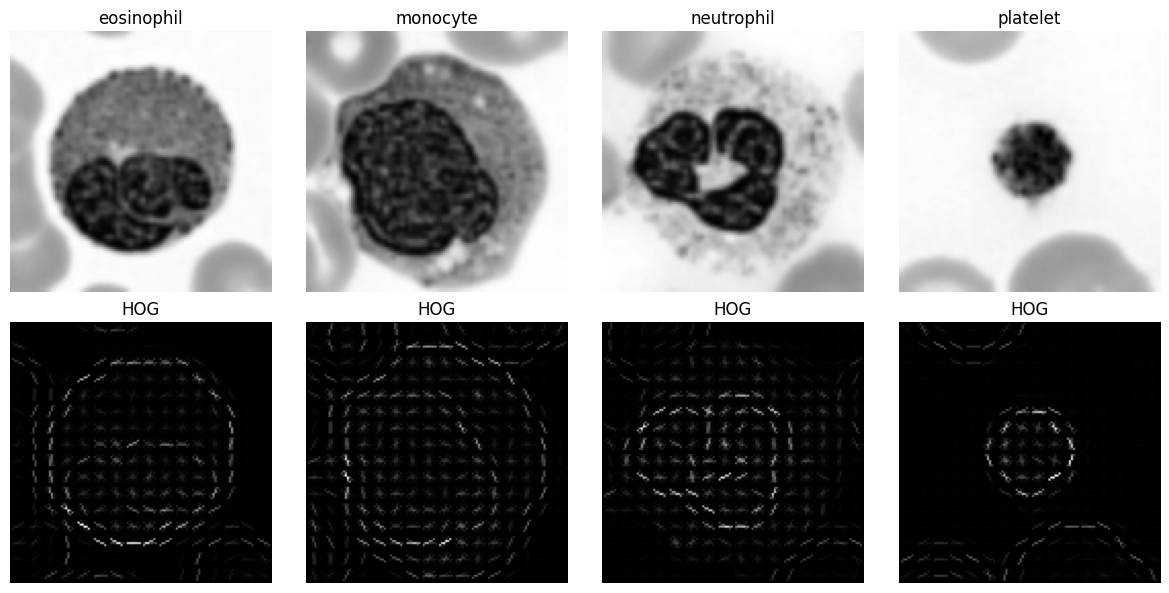

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for col, label in enumerate(CLASS_IDS):
    image = X_train[np.flatnonzero(y_train == label)[0]]
    _, picture = hog_features(image, visualize=True)
    axes[0, col].imshow(image, cmap="gray")
    axes[0, col].set_title(NAME_BY_ID[label])
    axes[1, col].imshow(picture, cmap="gray")
    axes[1, col].set_title("HOG")
    axes[0, col].axis("off")
    axes[1, col].axis("off")
plt.tight_layout()
plt.show()


### Choose C on validation and report metrics (3 marks)
Try exactly C ∈ {0.1, 1, 10}. Each pipeline fits its scaler and SVM on training features only. Select the highest validation accuracy; a tie keeps the smaller C because candidates are tried in ascending order. Report macro-F1 as well, which weights all classes equally. Confusion-matrix rows are true classes and columns are predicted classes.

The selected fitted model is retained unchanged for Q4; it is not refitted on validation data.

Training C=0.1...
Finished C=0.1: accuracy=0.7333, macro-F1=0.7316
Training C=1...
Finished C=1: accuracy=0.7333, macro-F1=0.7316
Training C=10...
Finished C=10: accuracy=0.7333, macro-F1=0.7316


,C,validation accuracy,macro-F1
0,0.1,0.733333,0.73165
1,1.0,0.733333,0.73165
2,10.0,0.733333,0.73165


HOG + SVM selected C: 0.1
Validation accuracy: 0.7333333333333333
Validation macro-F1: 0.7316497454048683


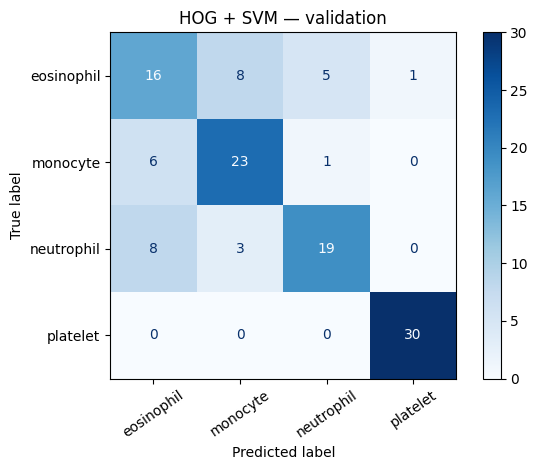

In [8]:
def choose_svm(train_features, val_features, title):
    best_model = None
    best_accuracy = -1
    rows = []
    for C in [0.1, 1, 10]:
        print(f"Training C={C}...", flush=True)
        model = make_pipeline(StandardScaler(),
                              LinearSVC(C=C, random_state=SEED, dual=True,
                                        max_iter=20000))
        model.fit(train_features, y_train)
        prediction = model.predict(val_features)
        accuracy = accuracy_score(y_val, prediction)
        macro_f1 = f1_score(y_val, prediction, average="macro", zero_division=0)
        print(
          f"Finished C={C}: accuracy={accuracy:.4f}, macro-F1={macro_f1:.4f}",
          flush=True
        )
        rows.append({"C": C, "validation accuracy": accuracy, "macro-F1": macro_f1})
        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_model = model
            best_C = C

    display(pd.DataFrame(rows))
    prediction = best_model.predict(val_features)
    print(title, "selected C:", best_C)
    print("Validation accuracy:", accuracy_score(y_val, prediction))
    print("Validation macro-F1:", f1_score(y_val, prediction, average="macro", zero_division=0))
    matrix = confusion_matrix(y_val, prediction, labels=CLASS_IDS)
    ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(cmap="Blues", xticks_rotation=35)
    plt.title(title + " — validation")
    plt.tight_layout()
    plt.show()
    return best_model

hog_model = choose_svm(H_train, H_val, "HOG + SVM")


## Q3. SIFT + SVM (7 marks)
### Normal SIFT detection (2 marks)
Run `detectAndCompute` on every training image and count the detected keypoints. OpenCV SIFT expects uint8 grayscale input, so convert [0, 1] floats back to [0, 255] integers. The picture uses a training image with the most detected keypoints.

**Why this is a problem for an SVM:** Different keypoint counts produce different-length concatenated descriptors, but an SVM requires the same number of features for every image.

Training images: 400
Average keypoints: 72.28
Minimum keypoints: 10
Maximum keypoints: 188
Images with zero keypoints: 0


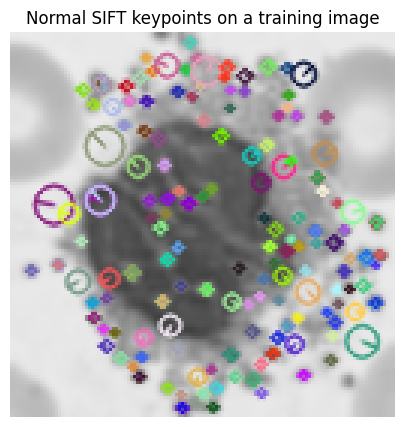

In [9]:
sift = cv2.SIFT_create()

def to_uint8(image):
    return np.round(np.clip(image, 0, 1) * 255).astype(np.uint8)

keypoint_counts = []
for image in X_train:
    keypoints, descriptors = sift.detectAndCompute(to_uint8(image), None)
    keypoint_counts.append(len(keypoints))
keypoint_counts = np.array(keypoint_counts)
print("Training images:", len(keypoint_counts))
print("Average keypoints:", keypoint_counts.mean())
print("Minimum keypoints:", keypoint_counts.min())
print("Maximum keypoints:", keypoint_counts.max())
print("Images with zero keypoints:", np.sum(keypoint_counts == 0))
example = to_uint8(X_train[np.argmax(keypoint_counts)])
keypoints, _ = sift.detectAndCompute(example, None)
picture = cv2.drawKeypoints(example, keypoints, None,
                           flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(picture, cv2.COLOR_BGR2RGB))
plt.title("Normal SIFT keypoints on a training image")
plt.axis("off")
plt.show()


### Fixed-grid SIFT and hand calculation (2 marks)
Place keypoints at the centers of a regular 6 × 6 grid, each with size 32. `sift.compute` describes these supplied points instead of detecting a variable number. Flatten descriptors in the same grid order for every image.

**Feature length = 6 × 6 grid points × 128 values = 4,608.** Keypoint angle is fixed at 0 degrees: this simple dense descriptor does not perform SIFT's detected-keypoint orientation assignment. Therefore, rotation robustness must be measured rather than assumed.

In [10]:
def grid_sift_features(image):
    positions = (np.arange(SIFT_GRID) + 0.5) * 128 / SIFT_GRID
    keypoints = [cv2.KeyPoint(float(x), float(y), 32, 0)
                 for y in positions for x in positions]
    computed_points, descriptors = sift.compute(to_uint8(image), keypoints)
    assert descriptors is not None
    assert len(computed_points) == SIFT_GRID ** 2
    assert descriptors.shape == (SIFT_GRID ** 2, 128)
    return descriptors.flatten()

S_train = np.array([grid_sift_features(image) for image in X_train])
S_val = np.array([grid_sift_features(image) for image in X_val])
print("Grid SIFT train shape:", S_train.shape)
print("Grid SIFT feature length:", S_train.shape[1])
print("Hand calculation:", SIFT_GRID, "x", SIFT_GRID, "x 128 =", SIFT_GRID ** 2 * 128)
assert S_train.shape[1] == SIFT_GRID ** 2 * 128


Grid SIFT train shape: (400, 4608)
Grid SIFT feature length: 4608
Hand calculation: 6 x 6 x 128 = 4608


### Choose C and report validation metrics (3 marks)
Use the same training-only scaling and validation selection procedure as HOG, making the comparison consistent.

Training C=0.1...
Finished C=0.1: accuracy=0.7083, macro-F1=0.7083
Training C=1...
Finished C=1: accuracy=0.7167, macro-F1=0.7175
Training C=10...
Finished C=10: accuracy=0.7167, macro-F1=0.7175


,C,validation accuracy,macro-F1
0,0.1,0.708333,0.708303
1,1.0,0.716667,0.717466
2,10.0,0.716667,0.717466


SIFT + SVM selected C: 1
Validation accuracy: 0.7166666666666667
Validation macro-F1: 0.7174662046407465


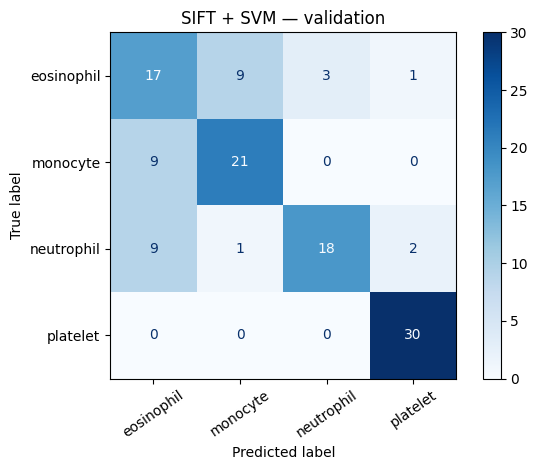

In [12]:
sift_model = choose_svm(S_train, S_val, "SIFT + SVM")




## Q4. Robustness (6 marks)
The prediction at the beginning addresses the first mark. **Both selected models are now frozen.** Transform test images before extracting features. Rotation is +20 degrees about the center, with reflected borders and a fixed 128 × 128 output. Noise is zero-mean Gaussian with σ = 0.05 on [0, 1] pixels, followed by clipping. Both models receive exactly the same transformed images. No C values are changed after looking at test results.

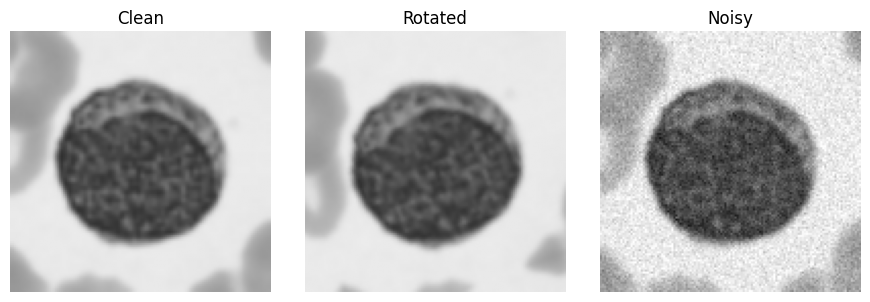

,Clean accuracy,Rotated accuracy,Noisy accuracy
Model,,,
HOG + SVM,0.7750,0.6750,0.2500
SIFT + SVM,0.7833,0.7333,0.7833


Each accuracy uses 120 test images; values are fractions from 0 to 1.


In [13]:
rotation_matrix = cv2.getRotationMatrix2D((63.5, 63.5), 20, 1.0)
rotated_test = np.array([
    cv2.warpAffine(image, rotation_matrix, (128, 128),
                   flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
    for image in X_test
])
noise_rng = np.random.default_rng(SEED)
noisy_test = np.clip(X_test + noise_rng.normal(0, 0.05, X_test.shape), 0, 1).astype(np.float32)
test_cases = {"Clean": X_test, "Rotated": rotated_test, "Noisy": noisy_test}
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, (case, images) in zip(axes, test_cases.items()):
    ax.imshow(images[0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(case)
    ax.axis("off")
plt.tight_layout()
plt.show()

results = []
clean_predictions = {}
for name, model, extractor in [
    ("HOG + SVM", hog_model, hog_features),
    ("SIFT + SVM", sift_model, grid_sift_features),
]:
    row = {"Model": name}
    for case, images in test_cases.items():
        features = np.array([extractor(image) for image in images])
        prediction = model.predict(features)
        row[case + " accuracy"] = accuracy_score(y_test, prediction)
        if case == "Clean":
            clean_predictions[name] = prediction
    results.append(row)
results = pd.DataFrame(results).set_index("Model")
display(results.style.format("{:.4f}"))
print("Each accuracy uses", len(y_test), "test images; values are fractions from 0 to 1.")


### Check the prediction in three sentences (1 mark)
The next cell prints an answer using the observed drops in accuracy. A drop is clean accuracy minus perturbed accuracy; negative values mean accuracy improved. A tie does not support the prediction that HOG loses more.

In [14]:
drops = pd.DataFrame({
    "Rotation drop": results["Clean accuracy"] - results["Rotated accuracy"],
    "Noise drop": results["Clean accuracy"] - results["Noisy accuracy"],
})
display(drops.style.format("{:.4f}"))
rotation_correct = drops.loc["HOG + SVM", "Rotation drop"] > drops.loc["SIFT + SVM", "Rotation drop"]
noise_correct = drops.loc["HOG + SVM", "Noise drop"] > drops.loc["SIFT + SVM", "Noise drop"]
print(f"My rotation prediction was {'supported' if rotation_correct else 'not supported'}: HOG lost {drops.loc['HOG + SVM', 'Rotation drop']:.4f} accuracy and SIFT lost {drops.loc['SIFT + SVM', 'Rotation drop']:.4f}.")
print(f"My noise prediction was {'supported' if noise_correct else 'not supported'}: HOG lost {drops.loc['HOG + SVM', 'Noise drop']:.4f} accuracy and SIFT lost {drops.loc['SIFT + SVM', 'Noise drop']:.4f}.")
print("These results describe this sampled test set and fixed-grid SIFT implementation, so they do not establish a universal ranking of the descriptors.")


,Rotation drop,Noise drop
Model,,
HOG + SVM,0.1000,0.5250
SIFT + SVM,0.0500,0.0000


My rotation prediction was supported: HOG lost 0.1000 accuracy and SIFT lost 0.0500.
My noise prediction was supported: HOG lost 0.5250 accuracy and SIFT lost 0.0000.
These results describe this sampled test set and fixed-grid SIFT implementation, so they do not establish a universal ranking of the descriptors.


## Q5. Short answers and AI log (3 marks)
### (a) Why HOG uses block normalization (1 mark shared with b)
HOG normalizes nearby cells together so that the descriptor depends less on overall gradient strength caused by lighting or contrast. This helps preserve the relative edge-direction pattern; the code above explicitly uses `block_norm="L2-Hys"`.

### (b) Why choosing C on the test set is wrong
Choosing C using test results lets test information influence the model, making the reported test score an optimistically biased evaluation. Our printed C tables use validation labels only, and test predictions first appear in Q4.

### Most confused classes (1 mark)
Count both directions of each pair in the **clean test** confusion matrices already produced in Q4. The next cell reports the most confused pair for each model, including ties and the case of no errors. The explanation about grayscale is a possible mechanism, not a demonstrated cause; proving it would require a separate color comparison.

In [15]:
for name, prediction in clean_predictions.items():
    matrix = confusion_matrix(y_test, prediction, labels=CLASS_IDS)
    print("\n" + name + " — clean test confusion counts")
    display(pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES))
    pairs = [(matrix[i, j] + matrix[j, i], CLASS_NAMES[i], CLASS_NAMES[j])
             for i in range(4) for j in range(i + 1, 4)]
    maximum = max(count for count, _, _ in pairs)
    if maximum == 0:
        print("No classes were confused on the clean test set.")
    else:
        for count, first, second in pairs:
            if count == maximum:
                print(f"Most confused pair: {first} and {second} ({count} errors in both directions combined).")
print("Grayscale removes color differences in staining that might help separate blood-cell classes, leaving the classifiers to rely on intensity, shape and texture.")



HOG + SVM — clean test confusion counts


,eosinophil,monocyte,neutrophil,platelet
eosinophil,24,1,4,1
monocyte,7,22,1,0
neutrophil,8,5,17,0
platelet,0,0,0,30


Most confused pair: eosinophil and neutrophil (12 errors in both directions combined).

SIFT + SVM — clean test confusion counts


,eosinophil,monocyte,neutrophil,platelet
eosinophil,18,9,2,1
monocyte,6,23,1,0
neutrophil,3,2,24,1
platelet,0,0,1,29


Most confused pair: eosinophil and monocyte (15 errors in both directions combined).
Grayscale removes color differences in staining that might help separate blood-cell classes, leaving the classifiers to rely on intensity, shape and texture.


### AI log (1 mark)
The prompt below records the assistance requested. The checks are implemented in this notebook; run them and inspect their outputs before claiming you verified the result. Edit this log to record any changes you make yourself.

In [16]:
ai_log = pd.DataFrame([{
    "Prompt (one line)": "Create a simple Colab notebook for the attached HOG vs SIFT midterm, explain code, and follow the rubric; registration 026.",
    "Changes made in AI-assisted draft": "Set seed 26, HOG cell 8, SIFT grid 6; use validation-only C selection and fixed-grid SIFT; derive answers from results.",
    "Checks completed by this run": "Split counts asserted; HOG length asserted; SIFT descriptor shapes asserted; training images, HOG pictures and test transformations displayed; validation scores and test table printed."
}])
display(ai_log.T)
print("Reached the end: inspect the plots and results, and update the AI log with your own checks.")


,0
Prompt (one line),Create a simple Colab notebook for the attache...
Changes made in AI-assisted draft,"Set seed 26, HOG cell 8, SIFT grid 6; use vali..."
Checks completed by this run,Split counts asserted; HOG length asserted; SI...


Reached the end: inspect the plots and results, and update the AI log with your own checks.


### Results from the saved run

| Model | Clean accuracy | Rotated accuracy | Noisy accuracy |
|---|---:|---:|---:|
| HOG + SVM | 77.50% | 67.50% | 25.00% |
| SIFT + SVM | 78.33% | 73.33% | 78.33% |

Both original predictions were supported: HOG lost 10.00 percentage points under rotation compared with SIFT's 5.00, and HOG lost 52.50 points under noise compared with SIFT's 0.00. SIFT had higher accuracy in all three conditions in this run. Equal clean and noisy SIFT accuracies do not prove that every individual prediction stayed unchanged.

### Additional AI assistance recorded after execution

| Prompt (one line) | Change made | How the result was checked |
|---|---|---|
| The SVM cell runs a long time without output; help fix it. | Changed LinearSVC from dual=False to dual=True and added progress messages for each C. | The saved Colab outputs show completion for all three C values for both models, validation metrics, and the final test table. |
| Review my executed notebook and identify needed changes. | Filled in the title name, corrected the stale execution-status note, and added this results summary and assistance log. | Reviewed saved outputs: no error outputs; 100/30/30 images per class; HOG length 8,100; SIFT length 4,608; validation-selected C values and test results present. |


## Rubric and submission checklist

| Question | Evidence in this notebook | Marks |
|---|---|---:|
| Q1 | Shapes, class counts, 4 × 4 training image grid | 3 |
| Q2 | HOG length and hand calculation; four HOG pictures; validation C table, accuracy, macro-F1, matrix | 6 |
| Q3 | Detected-keypoint statistics and picture; SVM explanation; fixed-grid descriptors and hand calculation; validation results | 7 |
| Q4 | Prediction before experiments; frozen-model clean/rotation/noise table; three-sentence comparison | 6 |
| Q5 | Two short answers; measured most-confused pairs and grayscale explanation; AI log | 3 |
| **Total** | | **25** |

Before submission:
1. Enter your name in the title and settings cell. Run all cells from top to bottom and check there are no errors or convergence warnings.
2. Read the generated answers and inspect the pictures. Be ready to explain any code cell in two minutes.
3. Download the executed notebook using **File → Download → Download .ipynb** and name it **026_Ismail_LabMid.ipynb** with your actual name.
4. The exam also requests visible outputs in a Markdown file on GitHub and a PDF copy. Export the executed notebook with Jupyter `nbconvert --to markdown 026_Ismail_LabMid.ipynb`, and upload the generated Markdown plus its image folder to your repository. For PDF, export to HTML with `nbconvert --to html 026_Ismail_LabMid.ipynb`, open the HTML in a browser, and print to PDF; check all outputs are visible. These exports are submission steps, not substitutes for running the notebook.

**Execution status:** executed in Colab with outputs saved. The saved notebook contains no error outputs. HOG selected C = 0.1 and SIFT selected C = 1 using validation accuracy. Dataset downloads require an internet connection if the notebook is rerun.